# Figure 4: Carbon intensity and manufacturing-emission payback

In [131]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

In [132]:
df = pd.read_excel(
    "data/combined_dataset.xlsx",
    sheet_name="Carbon Intensity",
)

In [133]:
# ---
# Materials carbon intensity
# ---

# Technology columns
tech_cols = [
    "Bioenergy",
    "Coal",
    "Geothermal",
    "Hydro",
    "Natural Gas",
    "Nuclear",
    "Oil",
    "Solar PV",
    "Wind Onshore",
    "Wind Offshore",
]

# Aggregate by material group and convert to tCO2/MW
df_grouped = (
    df.groupby("Group")[tech_cols]
    .sum()
    / 1000
)

df_grouped = df_grouped.rename(
    columns={
        "Hydro": "Hydropower",
    }
)

# Transpose for plotting
df_plot = df_grouped.T

# Technology order
order = [
    "Bioenergy",
    "Coal",
    "Geothermal",
    "Hydropower",
    "Natural Gas",
    "Nuclear",
    "Oil",
    "Solar PV",
    "Wind Onshore",
    "Wind Offshore",
]

df_plot = df_plot.reindex(order)

# Replace missing values with zero
df_plot = df_plot.fillna(0)


In [134]:
# ---
# Style
# ---

# Minimum font size: 12 pt
FONT_BASE = 12.0
FONT_TICKS = 12.0
FONT_TECH = 12.0
FONT_GROUP = 13.0
FONT_SCENARIO = 12.0
FONT_TOTAL = 12.0
FONT_MANUFACTURING_LABEL = 12.0
FONT_AXIS_LABEL = 13.5
FONT_LEGEND = 12.0
FONT_PANEL_LABEL = 13.0

plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": FONT_BASE,
        "axes.linewidth": 0.70,
        "axes.labelsize": FONT_AXIS_LABEL,
        "xtick.labelsize": FONT_TICKS,
        "ytick.labelsize": FONT_TECH,
        "legend.fontsize": FONT_LEGEND,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.dpi": 600,
    }
)


# ---
# Colours
# ---

COLOR_MANUFACTURING = "#4F9AB8"
COLOR_FUEL = "#B94745"
COLOR_GRID = "#BFBFBF"
COLOR_TEXT = 'black' #"#222222"
COLOR_SECONDARY_TEXT ='black' # "#555555"
COLOR_BACKGROUND = "white"
COLOR_AXIS = 'black' #"#444444"
COLOR_GROUP_LINE = "#777777"


In [135]:
# ---
# Configuration
# ---

technology_col = "Technology"
CARBON_THRESHOLD = 25.0  # gCO2/kWh


# ---
# Technology groups - panel a
# ---

tech_groups = {
    "Fossil fuels": [
        "Coal",
        "Natural Gas",
        "Oil",
    ],
    "Core transition technologies": [
        "Solar PV",
        "Wind Onshore",
        "Wind Offshore",
        "Nuclear",
    ],
    "Other low-carbon technologies": [
        "Bioenergy",
        "Geothermal",
        "Hydropower",
    ],
}


In [136]:
# ---
# Prepare input
# ---

df_capacity = df_plot.copy()

if technology_col in df_capacity.columns:
    df_capacity = df_capacity.set_index(
        technology_col,
    )

# Harmonise naming
df_capacity = df_capacity.rename(
    index={
        "Hydro": "Hydropower",
    }
)

# Aggregate duplicate technologies if required
df_capacity = (
    df_capacity
    .groupby(df_capacity.index)
    .sum(numeric_only=True)
)


# ---
# Full technology set
# ---

all_techs = [
    tech
    for group in tech_groups.values()
    for tech in group
]

df_capacity = df_capacity.reindex(
    all_techs,
)

# Total manufacturing footprint in tCO2e/MW installed
capacity_input = df_capacity.sum(
    axis=1,
)


# ---
# Fuel footprint
# ---

# Fuel footprint in gCO2e/kWh electricity
fuel_footprint = {
    "Bioenergy": 12 / 0.38,
    "Coal": 317 / 0.44,
    "Geothermal": 0,
    "Hydropower": 0,
    "Natural Gas": 182 / 0.55,
    "Nuclear": 3,
    "Oil": 267 / 0.32,
    "Solar PV": 0,
    "Wind Onshore": 0,
    "Wind Offshore": 0,
}

fuel_series = (
    pd.Series(fuel_footprint)
    .reindex(all_techs)
    .fillna(0)
)


# ---
# Capacity factors
# ---

# Use typical / mean capacity factors for all panel-a scenarios.
capacity_factor_dict = {
    "Bioenergy": 0.636,
    "Coal": 0.600,
    "Geothermal": 0.838,
    "Hydropower": 0.451,
    "Natural Gas": 0.633,
    "Nuclear": 0.817,
    "Oil": 0.263,
    "Solar PV": 0.200,
    "Wind Onshore": 0.338,
    "Wind Offshore": 0.421,
}

cf_mean = pd.Series(capacity_factor_dict).reindex(all_techs)


# ---
# Lifespans from Figure 3
# ---

# Retired observed central estimate
retired_observed = {
    "Bioenergy": 17,
    "Coal": 56,
    "Geothermal": 23,
    "Hydropower": 86,
    "Natural Gas": 44,
    "Nuclear": 31,
    "Oil": 41,
    "Solar PV": 8,
    "Wind Offshore": 22,
    "Wind Onshore": 15,
}

# Technical lifespan bounds from Figure 3
technical_range = {
    "Bioenergy": (20, 45),
    "Coal": (20, 50),
    "Geothermal": (20, 100),
    "Hydropower": (30, 100),
    "Natural Gas": (30, 50),
    "Nuclear": (30, 80),
    "Oil": (20, 50),
    "Solar PV": (20, 35),
    "Wind Offshore": (25, 30),
    "Wind Onshore": (20, 40),
}

# KM summary from Figure 3.
# Priority for panel-a central value: mean > median > lower.
km_summary = {
    "Bioenergy": {"lower": 29, "median": 68, "upper": np.nan},
    "Coal": {"lower": 52, "median": 61, "upper": np.nan},
    "Geothermal": {"lower": 23, "median": np.nan, "upper": np.nan},
    "Hydropower": {"lower": 117, "median": np.nan, "upper": np.nan},
    "Natural Gas": {"lower": 45, "median": 62, "upper": np.nan},
    "Nuclear": {"lower": 30, "median": 45, "upper": np.nan},
    "Oil": {"lower": 37, "median": 58, "upper": np.nan},
    "Solar PV": {"lower": 27, "median": 29, "upper": np.nan},
    "Wind Offshore": {"lower": 22, "median": 24, "upper": np.nan},
    "Wind Onshore": {"lower": 32, "median": 36, "upper": np.nan},
}


def get_km_preferred_value(summary_dict):
    if "mean" in summary_dict and np.isfinite(summary_dict["mean"]):
        return summary_dict["mean"]

    if "median" in summary_dict and np.isfinite(summary_dict["median"]):
        return summary_dict["median"]

    if "lower" in summary_dict and np.isfinite(summary_dict["lower"]):
        return summary_dict["lower"]

    return np.nan


life_retired = pd.Series(retired_observed).reindex(all_techs)
life_km = pd.Series(
    {
        tech: get_km_preferred_value(values)
        for tech, values in km_summary.items()
    }
).reindex(all_techs)
life_technical_mid = pd.Series(
    {
        tech: (bounds[0] + bounds[1]) / 2
        for tech, bounds in technical_range.items()
    }
).reindex(all_techs)


In [137]:
# ---
# Panel a - manufacturing intensity
# ---

# gCO2e/kWh =
# 1000 * tCO2e/MW / (CF * 8760 * lifespan)

def manufacturing_intensity_from_life(life_series):
    conversion_factor = 1000 / (
        cf_mean
        * 8760
        * life_series
    )

    return capacity_input * conversion_factor


manufacturing_retired = manufacturing_intensity_from_life(
    life_retired,
)

manufacturing_km = manufacturing_intensity_from_life(
    life_km,
)

manufacturing_technical = manufacturing_intensity_from_life(
    life_technical_mid,
)


# ---
# Panel a - build dataframe
# ---

scenario_labels = [
    "Ret",
    "KM",
    "Tech",
]

df_scenarios = pd.DataFrame(
    {
        ("Ret", "Manufacturing"): manufacturing_retired,
        ("Ret", "Fuel"): fuel_series,
        ("KM", "Manufacturing"): manufacturing_km,
        ("KM", "Fuel"): fuel_series,
        ("Tech", "Manufacturing"): manufacturing_technical,
        ("Tech", "Fuel"): fuel_series,
    }
).reindex(all_techs)


# ---
# Panel a - order within groups
# ---

# Order using the retired-observation total intensity
retired_total = (
    df_scenarios[("Ret", "Manufacturing")]
    + df_scenarios[("Ret", "Fuel")]
)

ordered_groups = {}

for group_name, group_techs in tech_groups.items():
    available = [
        tech
        for tech in group_techs
        if tech in df_scenarios.index
    ]

    ordered_groups[group_name] = sorted(
        available,
        key=lambda tech: retired_total.loc[tech],
        reverse=True,
    )


In [138]:
# ---
# Panel b - technology groups
# ---

tech_groups_b = {
    "Fossil fuels": [
        "Oil",
        "Coal",
        "Natural Gas",
    ],
    "Core transition technologies": [
        "Solar PV",
        "Wind Onshore",
        "Wind Offshore",
        "Nuclear",
    ],
    "Other low-carbon technologies": [
        "Bioenergy",
        "Geothermal",
        "Hydropower",
    ],
}

tech_order_b = [
    tech
    for group in tech_groups_b.values()
    for tech in group
]


# ---
# Panel b - capacity factors
# ---

# Use the same capacity factors as panel a
typical_cf_b = cf_mean.reindex(
    tech_order_b,
)


# ---
# Panel b - manufacturing footprint
# ---

E_man_b = (
    pd.Series(capacity_input)
    .reindex(tech_order_b)
    .astype(float)
)

if E_man_b.isna().any():
    missing = (
        E_man_b[
            E_man_b.isna()
        ]
        .index
        .tolist()
    )

    raise ValueError(
        "Missing manufacturing footprint for: "
        + ", ".join(missing)
    )


# ---
# Panel b - threshold calculation
# ---

# Electricity generated per MW installed
generation_required_kwh_b = (
    E_man_b
    * 1_000_000
    / CARBON_THRESHOLD
)

# 1 million kWh = 1 GWh
generation_required_mkwh_b = (
    generation_required_kwh_b
    / 1_000_000
)


# ---
# Panel b - equivalent operating years
# ---

years_required_b = (
    generation_required_kwh_b
    / (
        1000
        * 8760
        * typical_cf_b
    )
)

df_panel_b = pd.DataFrame(
    {
        "Manufacturing footprint (tCO2/MW)": E_man_b,
        "Typical capacity factor": typical_cf_b,
        "Generation required (kWh/MW)": generation_required_kwh_b,
        "Generation required (GWh/MW)": generation_required_mkwh_b,
        "Years of typical operation": years_required_b,
    }
)


# ---
# Panel a - grouped y positions
# ---

BAR_HEIGHT = 0.28

scenario_offsets = {
    "Ret": -0.34,
    "KM": 0.00,
    "Tech": 0.34,
}

TECH_SPACING = 1.18
GROUP_GAP = 0.75

y_positions = {}
group_header_positions = {}
group_line_positions = {}

current_y = 0.0

for group_name, techs in ordered_groups.items():
    if len(techs) == 0:
        continue

    first_y = current_y

    group_header_positions[group_name] = (
        first_y - 0.95
    )

    group_line_positions[group_name] = (
        first_y - 0.68
    )

    for tech in techs:
        y_positions[tech] = current_y
        current_y += TECH_SPACING

    current_y += GROUP_GAP

ordered_techs = [
    tech
    for group_name in ordered_groups
    for tech in ordered_groups[group_name]
]

df_scenarios = df_scenarios.reindex(
    ordered_techs,
)


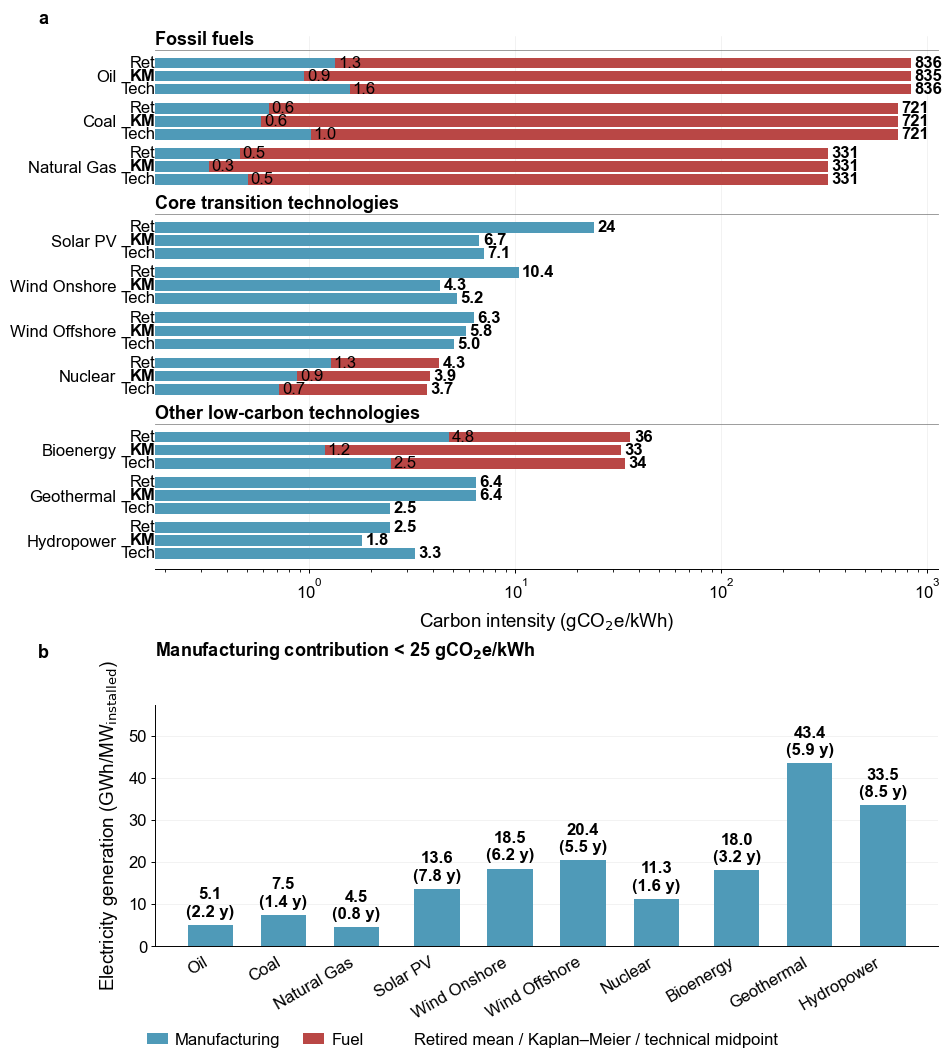

In [139]:
# ---
# Complete figure
# ---

fig = plt.figure(
    figsize=(9.6, 11.6),
    facecolor=COLOR_BACKGROUND,
)

outer = fig.add_gridspec(
    2,
    1,
    height_ratios=[
        2.10,
        0.95,
    ],
    hspace=0.35,
)


# ---
# Panel a - single axis
# ---

ax_a = fig.add_subplot(
    outer[0, 0],
)


# ---
# Panel b - single horizontal-bar axis
# ---

ax_b = fig.add_subplot(
    outer[1, 0],
)

for ax in [
    ax_a,
    ax_b,
]:
    ax.set_facecolor(
        COLOR_BACKGROUND,
    )


# ---
# Panel a - group headings
# ---

for group_name in ordered_groups:
    if group_name not in group_header_positions:
        continue

    ax_a.text(
        0.0,
        group_header_positions[group_name],
        group_name,
        transform=ax_a.get_yaxis_transform(),
        ha="left",
        va="center",
        fontsize=FONT_GROUP,
        fontweight="bold",
        color=COLOR_TEXT,
        clip_on=False,
        zorder=6,
    )


# ---
# Panel a - bars
# ---

xmin_positive = []
xmax_total = []

for tech in ordered_techs:
    y_center = y_positions[tech]

    for scen in scenario_labels:
        y = (
            y_center
            + scenario_offsets[scen]
        )

        manufacturing_value = df_scenarios.loc[
            tech,
            (
                scen,
                "Manufacturing",
            ),
        ]

        fuel_value = df_scenarios.loc[
            tech,
            (
                scen,
                "Fuel",
            ),
        ]

        total_value = (
            manufacturing_value
            + fuel_value
        )

        if np.isfinite(manufacturing_value) and manufacturing_value > 0:
            xmin_positive.append(manufacturing_value)

        if np.isfinite(total_value) and total_value > 0:
            xmax_total.append(total_value)

        # Manufacturing
        ax_a.barh(
            y,
            manufacturing_value,
            height=BAR_HEIGHT,
            color=COLOR_MANUFACTURING,
            edgecolor="none",
            zorder=3,
        )

        # Fuel
        ax_a.barh(
            y,
            fuel_value,
            left=manufacturing_value,
            height=BAR_HEIGHT,
            color=COLOR_FUEL,
            edgecolor="none",
            alpha=1,
            zorder=3,
        )

        # Scenario label at left margin
        scen_label = scen

        ax_a.text(
            -0.0,
            y,
            scen_label,
            transform=ax_a.get_yaxis_transform(),
            va="center",
            ha="right",
            fontsize=FONT_SCENARIO,
            fontweight=(
                "bold" if scen == "KM" else "normal"
            ),
            color=COLOR_SECONDARY_TEXT,
            zorder=5,
            clip_on=False,
        )

        # Total intensity label
        if np.isfinite(total_value) and total_value > 0:
            total_label = (
                f"{int(round(total_value))}"
                if total_value >= 20
                else f"{total_value:.1f}"
            )

            label_x = total_value * 1.04

            ax_a.text(
                label_x,
                y,
                total_label,
                va="center",
                ha="left",
                fontsize=FONT_TOTAL,
                fontweight="bold",
                color=COLOR_TEXT,
                zorder=5,
                clip_on=False,
            )

        # Manufacturing-only label for fossil and bioenergy
        if (
            tech in [
                "Bioenergy",
                "Nuclear",
                "Coal",
                "Natural Gas",
                "Oil",
            ]
            and np.isfinite(manufacturing_value)
            and manufacturing_value > 0
        ):
            manufacturing_label = (
                f"{int(round(manufacturing_value))}"
                if manufacturing_value >= 10
                else f"{manufacturing_value:.1f}"
            )

            ax_a.text(
                manufacturing_value * 1.03,
                y,
                manufacturing_label,
                va="center",
                ha="left",
                fontsize=FONT_MANUFACTURING_LABEL,
                fontweight="normal",
                color=COLOR_SECONDARY_TEXT,
                zorder=6,
                clip_on=False,
            )


# ---
# Panel a - axis limits
# ---

last_y = max(
    y_positions.values(),
)

ax_a.set_ylim(
    last_y + 0.75,
    -1.05,
)

x_min = min(xmin_positive) * 0.55
x_max = max(xmax_total) * 1.35

ax_a.set_xscale("log")
ax_a.set_xlim(
    x_min,
    x_max,
)


# ---
# Panel a - y labels
# ---

yticks = [
    y_positions[tech]
    for tech in ordered_techs
]

ax_a.set_yticks(
    yticks,
)

ax_a.set_yticklabels(
    ordered_techs,
    fontsize=FONT_TECH,
    color=COLOR_TEXT,
)

ax_a.tick_params(
    axis="y",
    length=0,
    colors=COLOR_TEXT,
    labelsize=FONT_TECH,
    pad=28,
)


# ---
# Panel a - grid and spines
# ---

ax_a.grid(
    axis="x",
    color=COLOR_GRID,
    linewidth=0.45,
    alpha=0.30,
    zorder=0,
)

ax_a.grid(
    axis="y",
    visible=False,
)

ax_a.set_axisbelow(
    True,
)

for spine in [
    "top",
    "right",
    "left",
]:
    ax_a.spines[spine].set_visible(
        False,
    )

ax_a.spines["bottom"].set_color(
    COLOR_AXIS,
)

ax_a.spines["bottom"].set_linewidth(
    0.70,
)

ax_a.tick_params(
    axis="x",
    direction="out",
    length=3.0,
    width=0.70,
    colors=COLOR_TEXT,
    labelsize=FONT_TICKS,
    pad=3,
)


# ---
# Panel a - panel label
# ---

ax_a.text(
    -0.15,
    1.015,
    "a",
    transform=ax_a.transAxes,
    ha="left",
    va="bottom",
    fontsize=FONT_PANEL_LABEL,
    fontweight="bold",
    color=COLOR_TEXT,
)


# ---
# Panel b - grouped vertical bars
# ---

xmax_b = float(
    generation_required_mkwh_b.max()
)

ymax_b = float(
    generation_required_mkwh_b.max()
)

# Build x positions with a small gap between groups.
GROUP_GAP_B = 0.1
BAR_WIDTH_B = 0.62

panel_b_positions = {}
panel_b_group_ranges = {}
panel_b_order = []

current_x_b = 0.0

for group_name, techs in tech_groups_b.items():
    group_start = current_x_b

    for tech in techs:
        panel_b_positions[tech] = current_x_b
        panel_b_order.append(tech)
        current_x_b += 1.0

    group_end = current_x_b - 1.0
    panel_b_group_ranges[group_name] = (
        group_start,
        group_end,
    )

    current_x_b += GROUP_GAP_B


# Bars and labels
for tech in panel_b_order:
    x = panel_b_positions[tech]
    value = generation_required_mkwh_b.loc[tech]
    years = years_required_b.loc[tech]

    ax_b.bar(
        x,
        value,
        width=BAR_WIDTH_B,
        color=COLOR_MANUFACTURING,
        edgecolor='none',
        zorder=3,
    )

    ax_b.text(
        x,
        value + ymax_b * 0.03,
        (
            f'{value:.1f}\n'
            f'({years:.1f} y)'
        ),
        va='bottom',
        ha='center',
        fontsize=FONT_TOTAL,
        fontweight='bold',
        color=COLOR_TEXT,
        clip_on=False,
        zorder=5,
    )


# Technology labels
ax_b.set_xticks(
    [
        panel_b_positions[tech]
        for tech in panel_b_order
    ]
)

ax_b.set_xticklabels(
    panel_b_order,
    fontsize=FONT_TECH,
    color=COLOR_TEXT,
    rotation=30,
    ha='right',
)


# ---
# Panel b - vertical group markers
# ---

# # Draw a vertical separator line after each group except the last.
# group_items = list(panel_b_group_ranges.items())
# for idx, (group_name, (group_start, group_end)) in enumerate(group_items):
#     group_mid = (group_start + group_end) / 2
#
#     ax_b.text(
#         group_mid,
#         1.04,
#         group_name,
#         transform=ax_b.get_xaxis_transform(),
#         ha='right',
#         va='bottom',
#         fontsize=FONT_GROUP,
#         fontweight='bold',
#         color=COLOR_TEXT,
#         clip_on=False,
#         zorder=5,
#     )
#
#     if idx < len(group_items) - 1:
#         next_group_start = group_items[idx + 1][1][0]
#         separator_x = next_group_start - 0.40
#         # separator_x = group_end + (GROUP_GAP_B / 2)
#         ax_b.axvline(
#             separator_x,
#             color=COLOR_GROUP_LINE,
#             linewidth=1.0,
#             alpha=0.90,
#             zorder=2,
#         )


# ---
# Panel b - axes
# ---

ax_b.set_xlim(
    -0.75,
    max(panel_b_positions.values()) + 0.75,
)

ax_b.set_ylim(
    0,
    ymax_b * 1.32,
)

ax_b.grid(
    axis='y',
    color=COLOR_GRID,
    linewidth=0.45,
    alpha=0.30,
    zorder=0,
)

ax_b.grid(
    axis='x',
    visible=False,
)

ax_b.set_axisbelow(
    True,
)

ax_b.tick_params(
    axis='x',
    length=0,
    pad=6,
    colors=COLOR_TEXT,
    labelsize=FONT_TECH,
)

ax_b.tick_params(
    axis='y',
    direction='out',
    length=3.0,
    width=0.70,
    colors=COLOR_TEXT,
    labelsize=FONT_TICKS,
    pad=3,
)

for spine in [
    'top',
    'right',
]:
    ax_b.spines[spine].set_visible(
        False,
    )

ax_b.spines['left'].set_color(
    COLOR_AXIS,
)

ax_b.spines['left'].set_linewidth(
    0.70,
)

ax_b.spines['bottom'].set_color(
    COLOR_AXIS,
)

ax_b.spines['bottom'].set_linewidth(
    0.70,
)

ax_b.set_ylabel(
    (
        r'Electricity generation '
        r'(GWh/MW$_\mathrm{installed}$)'
    ),
    fontsize=FONT_AXIS_LABEL,
    color=COLOR_TEXT,
    labelpad=6,
)


# ---
# Panel b - label and description
# ---

ax_b.text(
    -0.15,
    1.18,
    'b',
    transform=ax_b.transAxes,
    ha='left',
    va='bottom',
    fontsize=FONT_PANEL_LABEL,
    fontweight='bold',
    color=COLOR_TEXT,
)

ax_b.text(
    0.0,
    1.18,
    (
        rf'Manufacturing contribution < '
        rf'{CARBON_THRESHOLD:g} '
        rf'gCO$_\mathbf{{2}}$e/kWh'
    ),
    transform=ax_b.transAxes,
    ha='left',
    va='bottom',
    fontsize=FONT_GROUP,
    fontweight='bold',
    color=COLOR_TEXT,
)

# ---
# Complete figure layout
# ---

fig.subplots_adjust(
    left=0.18,
    right=0.995,
    top=0.985,
    bottom=0.20,
)

fig.canvas.draw()


# ---
# Panel a - x-axis label
# ---

panel_a_bottom = ax_a.get_position().y0

fig.text(
    (
        ax_a.get_position().x0
        + ax_a.get_position().x1
    ) / 2,
    panel_a_bottom - 0.045,
    r"Carbon intensity (gCO$_2$e/kWh)",
    ha="center",
    va="center",
    fontsize=FONT_AXIS_LABEL,
    color=COLOR_TEXT,
)


# ---
# Panel a - continuous group separator lines
# ---

x_fig_left = ax_a.get_position().x0
x_fig_right = ax_a.get_position().x1

for group_name in ordered_groups:
    if group_name not in group_line_positions:
        continue

    y_data = group_line_positions[group_name]

    y_display = ax_a.transData.transform(
        (
            0,
            y_data,
        )
    )[1]

    y_figure = (
        fig.transFigure
        .inverted()
        .transform(
            (
                0,
                y_display,
            )
        )[1]
    )

    separator = Line2D(
        [
            x_fig_left,
            x_fig_right,
        ],
        [
            y_figure,
            y_figure,
        ],
        transform=fig.transFigure,
        color=COLOR_GROUP_LINE,
        linewidth=0.60,
        alpha=0.85,
        zorder=1,
    )

    fig.add_artist(
        separator,
    )


# ---
# Legend
# ---

legend_elements = [
    Patch(
        facecolor=COLOR_MANUFACTURING,
        edgecolor="none",
        label="Manufacturing",
    ),
    Patch(
        facecolor=COLOR_FUEL,
        edgecolor="none",
        label="Fuel",
    ),
    Line2D(
        [0],
        [0],
        color="none",
        label=(
            "Retired mean / Kaplan–Meier / "
            "technical midpoint"
        ),
    ),
]

fig.legend(
    handles=legend_elements,
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(
        0.5,
        0.1,
    ),
    ncol=3,
    fontsize=FONT_LEGEND,
    columnspacing=1.35,
    handlelength=1.25,
    handletextpad=0.45,
)


# ---
# Save
# ---

plt.savefig(
    "figures/main/figure-4.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.savefig(
    "figures/main/figure-4.pdf",
    bbox_inches="tight",
    transparent=True,
)

plt.show()
